<a href="https://colab.research.google.com/github/Kush870/Unsupervised-Learning/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install numpy matplotlib scikit-learn pillow

Original Image Shape:  (416, 683)
Recontructed image shape :  (416, 683)


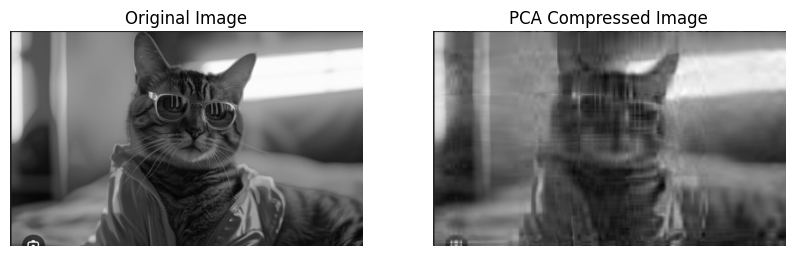

Original Data Size : 284128
Compressed Data Size : 5824
Number of Principal Componenets :  14
Evaluated Variance Ratio :  [0.68360475 0.09770819 0.06368358 0.03430958 0.02018733 0.01696359
 0.01087756 0.0073736  0.00609801 0.00590208 0.0050523  0.00412058
 0.00370177 0.00326068]
Total Variance Ratio :  0.9628436172796515


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA

#Step 1 : Load the image
image = Image.open("/content/Screenshot 2024-08-08 132904.png").convert("L")
##'L stands for luminance, a graysclae image node in the Pillow Library
#Each Pixel stores a single intensity value from 0 to 255

#Step 2 : Convert image into a numpy array
img_array = np.array(image)
print("Original Image Shape: ", img_array.shape)

#Step 3 : Apply PCA
pca = PCA(n_components = 0.96)

#Step 4 : Transform the Image
compressed_image = pca.fit_transform(img_array)

#Step 5 : Reconstruct the image
reconstructed_image = pca.inverse_transform(compressed_image)
print("Recontructed image shape : ", reconstructed_image.shape)

#Step 6 : Display original and compressed image
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img_array, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(reconstructed_image,cmap="gray")
plt.title("PCA Compressed Image")
plt.axis("off")

plt.show()


#Step 7 : Display Compression Information
print("Original Data Size :",img_array.size)
print("Compressed Data Size :",compressed_image.size)
print("Number of Principal Componenets : ", pca.n_components_)
print("Evaluated Variance Ratio : ", pca.explained_variance_ratio_)
print("Total Variance Ratio : ", pca.explained_variance_ratio_.sum())

Original Dataset shape :  (5000, 784)
Compressed dataset shape:  (5000, 252)


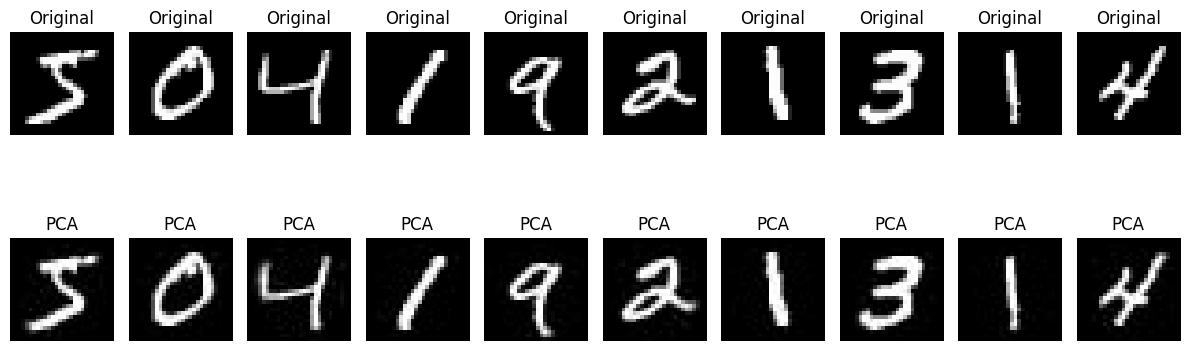

Original Features:  784
Compressed Features:  252
Explained variance ratio:  0.9801


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

#Load MNIST dataset
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

X= mnist.data

#Use a subset to make execution faster
#Select the first 5000 images to reduce execution time
X=X[:5000]

print("Original Dataset shape : ", X.shape)

#4. Normalise pixel values between 0 to 1
X=X/255.0

#5. Apply PCA
pca = PCA(n_components=0.98)

#6. Fit PCA and reduce dimensions
X_compressed = pca.fit_transform(X)

print("Compressed dataset shape: ",X_compressed.shape)

#7. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

#8. Display original and reconstructed images
plt.figure(figsize=(12,5))

for i in range(10):
  #Original Image
  plt.subplot(2,10,i+1)
  plt.imshow(X[i].reshape(28,28),cmap="gray")
  plt.title("Original")
  plt.axis("off")

  #Reconstructed Image
  plt.subplot(2,10,i+11)
  plt.imshow(X_reconstructed[i].reshape(28,28),cmap="gray",vmin=0,vmax=1)
  plt.title("PCA")
  plt.axis("off")
plt.tight_layout()
plt.show()

#Display compression information
print("Original Features: ", X.shape[1])
print("Compressed Features: ", pca.n_components_)
print("Explained variance ratio: ", round(pca.explained_variance_ratio_.sum(),4))

#Calculate Dimensionality reduction
reduction =